## A/B - тестирование


Внутри увидите пример как формируются результаты по аб-тестированию. Прочтите сначала его, затем приступайте к выполнению задания.

В папке присутствует файл ab_test_ensembles.csv , который содержит реальные данные ab теста, когда-то проходившего у меня. Вам необходимо провести стандартный пайплайн, начав с ознакомления данных до вывода отчета. Условие гипотезы такое же как и в примере, нам необходимо нашим новым вариантом увеличить коэффициент конверсии на 2%, коэффициенты конверсии одинаковы с файлом из примера (плюс/минус) поэтому с этим проблем быть не должно. Условия гипотез теже.

В A/B тесте было два варианта работы сервиса - standard и svm_ensemble_v_1_22, где работала модель классификации пользователей.

Ответьте на 2 вопроса:

1. Стоит ли нам оставить старый вариант работы или заменить на вариант svm_ensemble_v_1_22 (используем всю выборку 200к+ записей)
2. Так же посчитайте вывод для типа пользователей (user_type) стоит ли для новых/старых пользователей (new/registered user) оставить старый / новый вариант работы (разделяем всю выборку 200к+ записей на группы)

Также необходимо провести небольшое EDA по представленному датасету, нарисовать два графика на ваш вкус.

---

**Баллы могут быть снижены** за качество кода - старайтесь чтобы код был максимально лаконичным. Названия переменных (если они используются) должны отражать максимальную ее сущность.

**Комментарии по сдаче практического задания**:
1. Залить в репу на github в папку module_2/ab_test_inference
2. Ссылку на репо отправлять мне в тг не позднее дедлайна.
3. Тема письма: Домашнее задание по модулю 2 <Фамилия Имя>
4. После дедлайна, неотправленные задания, оцениваются максимум в 7 баллов.

Number of rows: 294478
Number of null values: 0
Number of duplicate user_ids: 0
Number of valid rows: 290585


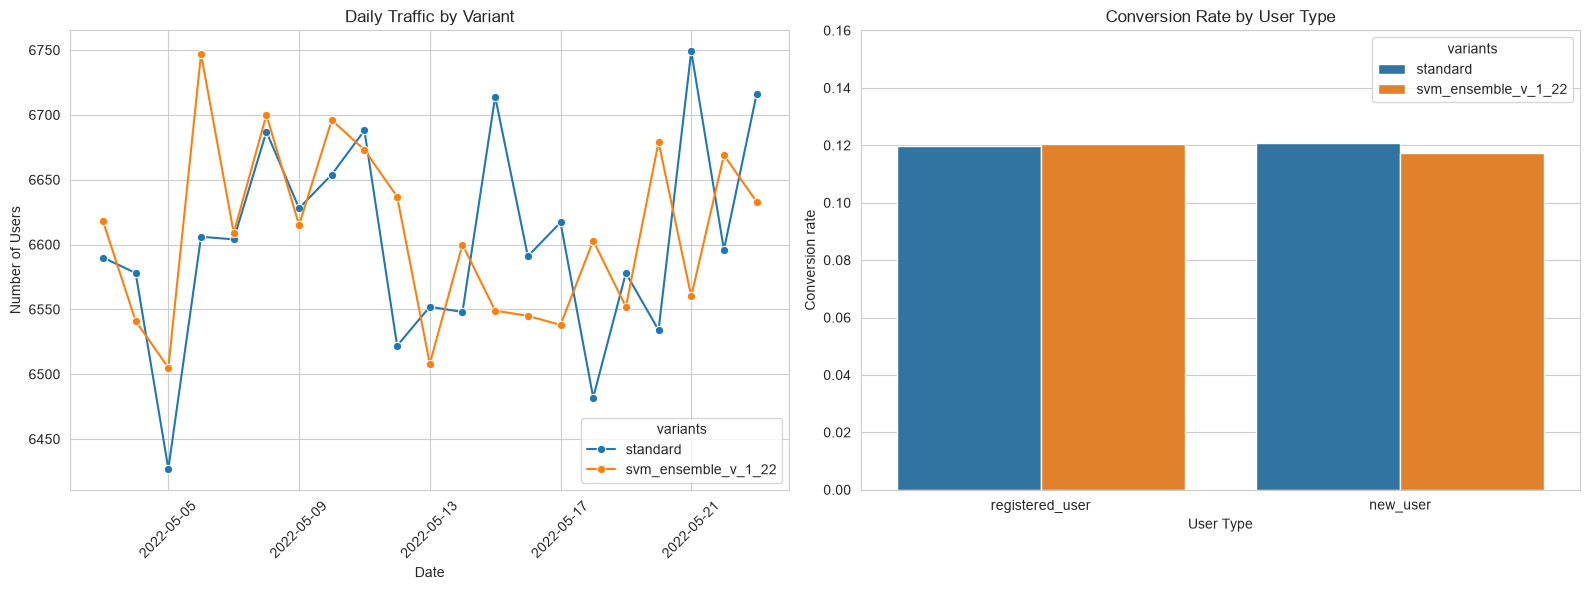

All Users
Control CR: 0.1203863045004612 | 95 CI: [0.11871294722381814, 0.12205966177710426] (n=145274)
Treatment CR: 0.11880724790277405 | 95 CI: [0.11714362162601945, 0.12047087417952866] (n=145311)
Z-statistic: 1.3116075339133115 | p-val: 0.18965258971881804
Segment new_user
Control CR: 0.12089406657416439 | 95 CI: [0.1185257903935982, 0.12326234275473058] (n=72791)
Treatment CR: 0.11732568085869595 | 95 CI: [0.11498291010371188, 0.11966845161368002] (n=72482)
Z-statistic: 2.0993871299249323 | p-val: 0.03578278829008374
Segment registered_user
Control CR: 0.11987638480747209 | 95 CI: [0.11751172501680657, 0.12224104459813762] (n=72483)
Treatment CR: 0.12028175589394334 | 95 CI: [0.11791927885278755, 0.12264423293509913] (n=72829)
Z-statistic: -0.23769281071383486 | p-val: 0.8121193601108101


In [5]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from statsmodels.stats.proportion import proportions_ztest, proportion_confint

def ztest(data, segment_name, alpha=0.05):
    control = data[data["group"] == "control"]["converted"]
    treatment = data[data["group"] == "treatment"]["converted"]

    successes = [control.sum(), treatment.sum()]
    nobs = [control.count(), treatment.count()]

    z_stat, p_val = proportions_ztest(successes, nobs=nobs)
    (lower_con, lower_treat), (upper_con, upper_treat) = proportion_confint(
        successes, nobs=nobs, alpha=alpha
    )

    print(f"{segment_name}")
    print(f"Control CR: {control.mean()} | 95 CI: [{lower_con}, {upper_con}] (n={nobs[0]})")
    print(f"Treatment CR: {treatment.mean()} | 95 CI: [{lower_treat}, {upper_treat}] (n={nobs[1]})")
    print(f"Z-statistic: {z_stat} | p-val: {p_val}")

 
#Данные
df = pd.read_csv('ab_test_ensembles.csv')

print(f"Number of rows: {len(df)}")
print(f"Number of null values: {df.isnull().sum().sum()}")
print(f"Number of duplicate user_ids: {df['user_id'].duplicated().sum()}")

is_valid_control = (df["group"] == "control") & (df["variants"] == "standard")
is_valid_treatment = (df["group"] == "treatment") & (df["variants"] == "svm_ensemble_v_1_22")

clean_ab_data = df[is_valid_control | is_valid_treatment].copy()
clean_ab_data["timestamp"] = pd.to_datetime(clean_ab_data["timestamp"])
clean_ab_data["date"] = clean_ab_data["timestamp"].dt.date

print(f"Number of valid rows: {len(clean_ab_data)}")

#Графики 
sns.set_style(style="whitegrid")
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

daily_traffic = (
    clean_ab_data
    .groupby(["date", "variants"])["user_id"]
    .count()
    .reset_index(name="users_count")
)
boundary_days = [daily_traffic["date"].min(), daily_traffic["date"].max()]
full_days_traffic = daily_traffic[~daily_traffic["date"].isin(boundary_days)]

sns.lineplot(
    data=full_days_traffic, 
    x="date", 
    y="users_count", 
    hue="variants", 
    marker='o', 
    ax=axes[0])
axes[0].set_title("Daily Traffic by Variant")
axes[0].set_xlabel("Date")
axes[0].set_ylabel("Number of Users")
axes[0].tick_params(axis='x', rotation=45)

sns.barplot(
    data=clean_ab_data,
    x="user_type",
    y="converted",
    hue="variants",
    errorbar=None,
    ax=axes[1]
)
axes[1].set_title('Conversion Rate by User Type')
axes[1].set_xlabel('User Type')
axes[1].set_ylabel('Conversion rate')
axes[1].set_ylim(0,0.16)

plt.tight_layout()
plt.show()

#Z-тесты
ztest(clean_ab_data, "All Users")

for user_type in ["new_user", "registered_user"]:
    subset = clean_ab_data[clean_ab_data["user_type"] == user_type]
    ztest(subset, f"Segment {user_type}")



# 1 Вопрос

Оставить старый вариант, не внедрять svm_ensemble_v_1_22.

All Users p-value = 0.1896 > 0.05, поэтому мы не можем отвергнуть нулевую гипотезу  — статистически значимой разницы между вариантами нет.

Конверсия svm_ensemble_v_1_22 составила 11.88% [11.71%, 12.04%] против 12.03% [11.8, 12.2] у standard (-0.15%). Новая модель не только не даёт целевого прироста конверсии, но и в среднем слегка уступает базовой версии.

# 2. Вопрос

Новые пользователи, оставить standard.
p-value = 0.0358 < 0.05, мы отвергаем нулевую гипотезу, различие статистически значимо, но оно отрицательное: конверсия упала с 12.08% до 11.73% (−0.36%). Новая модель статистически значимо ухудшает результат для новых пользователей.

Зарегистрированные пользователи, оставить standard:
p-value = 0.8121 > 0.05, мы не можем отвергнуть нулевую гипотезу. Небольшое различие между 11.98% и 12.02% (+0.04%) является случайным шумом, а 95% доверительный интервал [11.79%, 12.26%] далёк от целевого прироста +2%.